# Durable State — Reference Notebook (Week 2 Day 3)

This notebook builds UnderCover's claim agent as a **durable LangGraph graph**: an agent whose state survives
restarts, can pause mid-flight for a human decision, and never pays a claim twice.

**What it covers, in order:**

1. **Part 1 — Supabase**: connect to a managed Postgres database and set up the Supabase MCP server for Claude Code.
2. **Part 2 — From `create_agent` to a graph**: see that `create_agent` is itself a LangGraph graph, then rebuild the same shape by hand with `StateGraph`, adding a structured decision step, a human-approval pause and a payment step — checkpointed to Postgres.
3. **Part 3 — Pause for approval**: run claims through the graph. Small claims complete in one pass; a claim over the approval limit `interrupt`s and waits for a handler, then resumes with `Command(resume=...)`.
4. **Part 4 — Crash and carry on**: simulate a crash, reload the paused state from the checkpointer, resume, and prove payments are idempotent.

**Key ideas:** checkpointers persist graph state per `thread_id`; `interrupt()` is how a graph waits for a human;
`durability='sync'` writes each checkpoint before moving on; idempotent writes (`ON CONFLICT DO NOTHING`) make retries safe.

In [26]:
import json # For working with JSON data
import os # For interacting with the operating system
from pathlib import Path # For working with filesystem paths
from typing import Annotated, Literal, TypedDict # For working with type annotations, Literals, and TypedDicts
from urllib.parse import urlparse # For parsing URLs

import pandas as pd # For working with dataframes and tabular data
import psycopg # For working with PostgresSQL databases
from psycopg.rows import dict_row # For working with rows as dictionaries
from dotenv import load_dotenv # For loading environment variables from a .env file
from IPython.display import Image, display # For displaying images in Jupyter notebooks

from langchain.agents import create_agent # For creating language model agents
from langchain_core.messages import HumanMessage, SystemMessage # For working with human and system messages
from langchain_core.tools import tool # For working with language model tools
from langchain_openai import ChatOpenAI # For working with OpenAI language models

from langgraph.checkpoint.postgres import PostgresSaver # For saving checkpoints to a Postgres database
from langgraph.graph import END, START, StateGraph # For working with state graphs
from langgraph.graph.message import add_messages # For adding messages to the state graph
from langgraph.graph.message import add_messages # For adding messages to the state graph 
from langgraph.prebuilt import ToolNode # For working with prebuilt tool nodes
from langgraph.types import Command, interrupt # For working with command types and interruptions

from pydantic import BaseModel, Field # For working with Pydantic models and fields
from week2day1_payout import Benefit, Line, Payout, work_out_payout # For working with payout models and calculations


### Connect to OpenRouter

In [27]:
load_dotenv(override=True)

openrouter_api_key = os.getenv('OPENROUTER_API_KEY')
OPENROUTER_BASE_URL = 'https://openrouter.ai/api/v1'

if openrouter_api_key:
    print("OpenRouter API key is loaded and good to go")
else:
    print("OpenRouter API key is not loaded ")


OpenRouter API key is loaded and good to go


## Part 1: Supabase

Supabase gives us a managed Postgres database in the cloud. We connect once with `psycopg` using the
`DATABASE_URL` pooler string from `.env`, work in a dedicated `lab` schema so the lab's tables stay separate
from the product's, and use `dict_row` so query results come back as dictionaries.

In [28]:
DATABASE_URL = os.getenv('DATABASE_URL')

connection = psycopg.connect(DATABASE_URL,
                             autocommit=True,
                             prepare_threshold=0,
                             row_factory=dict_row,
                             options='-c search_path=lab')
connection.execute('CREATE SCHEMA IF NOT EXISTS lab')

print(connection.execute('SELECT version()').fetchone()['version'])

PostgreSQL 17.11 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 15.2.0, 64-bit


### The Supabase MCP server for Claude Code


In [29]:
project_ref = urlparse(DATABASE_URL).username.split('.')[1]
print(f'claude mcp add --transport http supabase "https://mcp.supabase.com/mcp?project_ref={project_ref}&read_only=true"')

claude mcp add --transport http supabase "https://mcp.supabase.com/mcp?project_ref=qshowtoibhrbdmxjmghm&read_only=true"


---
**Part 1 summary** — We now have a live Postgres connection (`connection`) pointed at the `lab` schema, with
`autocommit=True` so each statement commits immediately (required by the LangGraph checkpointer), and
`prepare_threshold=0` because Supabase's transaction pooler doesn't support prepared statements. We also
printed the one-line command that registers Supabase's read-only MCP server with Claude Code, so a coding
agent can inspect our tables during the product build.

## Part 2: From create_agent toa graph

This part shows that there is no magic in `create_agent`: it compiles down to a LangGraph `StateGraph`. We
first run a prebuilt agent on a claim, draw its graph, then rebuild the same shape by hand — which lets us
add our own nodes: a structured `decide` step, an `approval` pause and a `pay` step, with the whole graph
checkpointed to Postgres via `PostgresSaver`.

### The Claims

In [30]:
DATA = Path("../../../data")

def load(name):
    """ Read one of UnderCover's JSON files. """
    return json.loads((DATA / name).read_text(encoding='utf-8'))

claims = {claim['claim_id']: claim for claim in load("claims.json")}
policies = {policy['policy_id']:policy for policy in load('policies.json')}
policy_wording = (DATA / 'policy_wording.md').read_text(encoding='utf-8')
APPROVAL_LIMIT = load('company.json')['payout_approval_limit']

print(f"{len(claims)} claims. A payout over ${APPROVAL_LIMIT:,.0f} needs a handler's approval")

25 claims. A payout over $1,000 needs a handler's approval


### The agent workflow

In [31]:
INSTRUCTIONS = """ You are a claims handler at UnderCover Travel Insurance. Decide the claim you 
are given, using the policy wording below and the customer's policy record.

Choose one decision:
- approve: the wording covers the claim and the required documents are attached. Work out the payout using section 10.
- decline: the wording does not cover the claim.
- refer: a colleague needs to look at it, because a required document is missing, or the story and the documents disagree, or the wording does not settle the question.

Use the payout tool to work out the payout on an approved claim. When you have decided, give your decision, the payout and your reasons. 
"""

def make_user_prompt(claim):
    """ The customer's policy record and the claim, as JSON."""
    policy = policies[claim['policy_id']]
    return f"""# Policy record
    
    {json.dumps(policy, indent=2)}

    # Claim
    {json.dumps(claim, indent=2)}
    """

In [32]:
@tool(parse_docstring=True)
def calculate_payout(policy_id: str, benefit: Benefit, lines: list[Line], paid_by_others: float=0.0) -> Payout:
    """ Work out the payout on an approved claim with UnderCover's payout rules. 
    
    Args:
        policy_id: The customer's policy id.
        benefit: The benefit the claim is paid under.
        lines: The covered items and expenses, one for each line of the claim, with any excluded ones left out. A pair or a set counts as one item
        paid_by_others: Anything a carrier, hotel or other party has paid or refunded for the same loss

    Returns:
        The calculation, the payout and whether it needs sign-off
    """

    return work_out_payout(policies[policy_id], benefit, lines, paid_by_others)


In [33]:
luna = ChatOpenAI(
    model='openai/gpt-6-luna',
    base_url=OPENROUTER_BASE_URL,
    api_key=openrouter_api_key,
    reasoning_effort='low',
    timeout=120,
    max_retries=5
)

claims_agent = create_agent(
    model = luna,
    tools = [calculate_payout],
    system_prompt=f"{INSTRUCTIONS}\n{policy_wording}\n"
)

In [34]:
result = claims_agent.invoke(
    {
        'messages':[
            {
                'role': 'user',
                'content': make_user_prompt(claims['CLM-1005'])
            }
        ]
    }
)
print(result['messages'][-1].text)

**Decision: Approve**  
**Payout: $243.00**

The passport was destroyed during the covered trip, and the lodge manager’s letter confirms what happened and that it could no longer be used. The embassy, photo and taxi receipts document the replacement fees and reasonable local travel. These costs are covered under the Passport and Travel Documents benefit. The $243 total is within the Premium plan’s $250 maximum.


### create_agent builds a LangGraph graph

In [35]:
type(claims_agent)

langgraph.graph.state.CompiledStateGraph

In [36]:
print(claims_agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



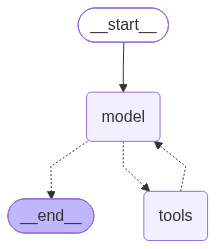

In [37]:
display(Image(claims_agent.get_graph().draw_mermaid_png()))

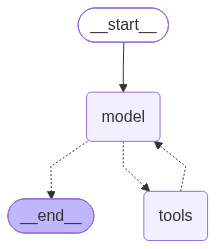

In [38]:
claims_agent

### The same shape by hand

In [39]:
class ClaimState(TypedDict): # Represents the state of a claim within the graph
    """ What the graph keeps for one claim within the state graph."""
    messages: Annotated[list, add_messages]
    claim_id: str
    decision: str
    payout: float
    rationale: str
    approved_by: str
    

In [40]:
class ClaimDecision(BaseModel): # Represents a decision made by a claims handler on a claim
    """ A claims handler's decision on one claim. """
    rationale: str = Field(description=" 2-3 sentences to explain the decision along with the relevant section of the policy")
    decision: Literal['approve', 'decline', 'refer']
    payout: float = Field(description="The amount to pay in US dollars, or 0 for a decline or a referral")


In [41]:
model_with_tools = luna.bind_tools([calculate_payout])
decider = luna.with_structured_output(ClaimDecision)
system_message = SystemMessage(f"{INSTRUCTIONS}\n{policy_wording}")

def agent(state: ClaimState): # Define the agent function
    """ Call the model with the conversation so far. """
    return {'messages': [model_with_tools.invoke([system_message, *state['messages']])]}

def decide(state: ClaimState): # Define the decision function
    """ Turn the agent's work into a decision"""
    result = decider.invoke([system_message, *state['messages'], HumanMessage('Record your decision on this claim.')])
    return {'decision': result.decision, 'payout': result.payout, 'rationale':result.rationale}

### Pausing for a handler

In [42]:
def approval(state: ClaimState): # Define the approval function
    """ Wait for a handler to approve a payout over the limit. """
    print(f"{state['claim_id']} needs a handler to approve ${state['payout']:,.2f}")
    answer = interrupt({'claim_id': state['claim_id'], 'payout': state['payout'], 'rationale': state['rationale']})
    return{'approved_by': answer['handler']}


### Paying the claim

In [43]:
connection.execute(""" 
CREATE TABLE IF NOT EXISTS payments(
claim_id TEXT PRIMARY KEY,
amount NUMERIC NOT NULL,
approved_by TEXT,
paid_at TIMESTAMPTZ DEFAULT now()
)""") # Create the payments table if it doesn't exist

def pay(state: ClaimState): # Record a payment for a claim
    """ Pay the claim, unless it has been paid already."""
    cursor = connection.execute(
        'INSERT INTO payments(claim_id, amount, approved_by) VALUES (%s, %s, %s) ON CONFLICT (claim_id) DO NOTHING',
        (state['claim_id'], state['payout'], state.get('approved_by')),
    )
    if cursor.rowcount:
        print(f"Paid {state['claim_id']} ${state['payout']:,.2f}")
    else:
        print(f"{state['claim_id']} was already paid")

### The edges


In [44]:
def after_agent(state: ClaimState): # Perform actions after the agent has processed the claim
    """ Run the tools the model asked for, or move on to the decision."""
    if state['messages'][-1].tool_calls:
        return 'tools' 
    return 'decide'

def after_decide(state: ClaimState): # Perform actions after the decision has been made
    """ Pay an approval after a handler's approval if it's over the limit. """
    if state['decision'] != 'approve':
        return END
    if state['payout']> APPROVAL_LIMIT:
        return 'approval' 
    return 'pay'

### The checkpointer

In [45]:
checkpointer = PostgresSaver(connection)
checkpointer.setup()

### Build the graph

In [46]:
builder = StateGraph(ClaimState) # Initializing the state graph for claim processing
builder.add_node('agent', agent) # Adding the agent node to the state graph
builder.add_node('tools', ToolNode([calculate_payout])) # Adding the tools node to the state graph
builder.add_node('decide', decide) # Adding the decision node to the state graph
builder.add_node('approval', approval) # Adding the approval node to the state graph
builder.add_node('pay', pay) # Adding the pay node to the state graph 

builder.add_edge(START, 'agent') # Connecting the start node to the agent node
builder.add_conditional_edges('agent', after_agent, ['tools', 'decide']) # Adding conditional edges from the agent node based on the after_agent function
builder.add_edge('tools', 'agent') # Connecting the tools node back to the agent node
builder.add_conditional_edges('decide', after_decide, ['approval', 'pay', END]) # Connecting the decision node to the appropriate next nodes based on the after_decide function
builder.add_edge('approval', 'pay') # Connecting the approval node to the pay node
builder.add_edge('pay', END) # Connecting the pay node to the end node 

graph = builder.compile(checkpointer=checkpointer)

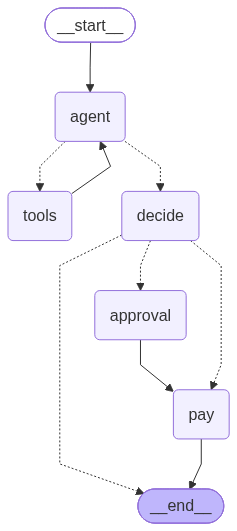

In [47]:
graph


---
**Part 2 summary** — The hand-built graph has five nodes and mirrors the shape `create_agent` produced, plus our business steps:

| Node | What it does |
|---|---|
| `agent` | Calls the model (with the payout tool bound) on the conversation so far |
| `tools` | Runs any tool calls the model asked for, then loops back to `agent` |
| `decide` | Forces a structured `ClaimDecision` (decision / payout / rationale) |
| `approval` | `interrupt()`s the graph and waits for a handler when the payout is over the limit |
| `pay` | Inserts the payment, idempotently, into the `payments` table |

Routing is done by two conditional edges: `after_agent` (tool calls → `tools`, otherwise → `decide`) and
`after_decide` (decline/refer → `END`, over the limit → `approval`, otherwise → `pay`). `PostgresSaver(connection)`
checkpoints every step to Supabase, keyed by `thread_id` — that's what makes the pause and the crash recovery possible.

## Part 3: Pause for approval

Now we run real claims through the graph, one `thread_id` per claim. A claim under the approval limit flows
straight through to payment. A claim over the limit stops at the `approval` node: `interrupt()` suspends the
graph, the checkpointer saves where it stopped, and `graph.invoke(Command(resume=...))` picks it up again
with the handler's answer.

In [48]:
def start_fresh(claim_id):
    """ Delete a claim's saved thread and its payment."""
    checkpointer.delete_thread(claim_id)
    connection.execute("DELETE FROM payments WHERE claim_id = %s", (claim_id,))
    

### A claim under the limit

In [49]:
start_fresh('CLM-1005')
config = {'configurable':  {'thread_id': 'CLM-1005'}}
claim = {'messages': [HumanMessage(make_user_prompt(claims['CLM-1005']))], 'claim_id': 'CLM-1005'}

result = graph.invoke(claim, config=config, durability='sync')
print(f"{result['decision']} ${result['payout']:,.2f}: {result['rationale']}")

Paid CLM-1005 $243.00
approve $243.00: The passport was damaged and made unusable during the covered trip, and the lodge letter and receipts support the incident and claimed replacement costs. Under section 6, replacement fees, photos and reasonable local travel to the embassy are covered; the $243 total is within the Premium plan’s $250 maximum.


### A claim over the limit

In [50]:
start_fresh('CLM-1003')
config = {'configurable': {'thread_id': 'CLM-1003'}}
claim = {'messages': [HumanMessage(make_user_prompt(claims['CLM-1003']))], 'claim_id': 'CLM-1003'}

result = graph.invoke(claim, config=config, durability='sync')
result = ["__interrupt__"]

CLM-1003 needs a handler to approve $3,750.00


In [51]:
graph.get_state(config).next

('approval',)

### The handler's approval

In [52]:
result = graph.invoke(Command(resume={'handler': 'Dana Whitfield'}), config, durability='sync')

CLM-1003 needs a handler to approve $3,750.00
Paid CLM-1003 $3,750.00


### Never pay twice

In [53]:
pay(graph.get_state(config).values)

CLM-1003 was already paid


---
**Part 3 summary** — CLM-1005 (under the limit) completed in a single `invoke`. CLM-1003 (over the limit)
paused at `approval` — `graph.get_state(config).next` showed `('approval',)` — and resumed when Dana
Whitfield approved it via `Command(resume={'handler': ...})`. Calling `pay()` again by hand proved the
`ON CONFLICT (claim_id) DO NOTHING` insert makes payment idempotent: the claim is never paid twice.

## Part 4: Crash and carry on

The real test of durability: a claim pauses for approval, and in the meantime the process could die entirely.
Because every step was checkpointed to Postgres with `durability='sync'`, a brand-new process can rebuild the
graph, load the saved state by `thread_id`, see exactly where it stopped and what it was waiting for, and
resume as if nothing happened.

In [54]:
start_fresh('CLM-1008')
config = {'configurable': {'thread_id': 'CLM-1008'}}
claim = {'messages': [HumanMessage(make_user_prompt(claims['CLM-1008']))], 'claim_id': 'CLM-1008'}
result = graph.invoke(claim, config, durability='sync')
result['__interrupt__']

CLM-1008 needs a handler to approve $2,240.00


[Interrupt(value={'claim_id': 'CLM-1008', 'payout': 2240.0, 'rationale': 'The tornado made the insured’s home uninhabitable, which is a covered cancellation reason under section 2. The county notice and supplier confirmations support the claim; after deducting the $200 airline credit from the $2,440 in documented prepaid costs, the payable amount is $2,240, within the Premium limit.'}, id='397fab63f70dcac1683a23eb63c65665', response_schema=None)]

In [55]:
config = {'configurable': {'thread_id': 'CLM-1008'}}
state = graph.get_state(config)

print(state.next)
print(state.interrupts[0].value)

('approval',)
{'claim_id': 'CLM-1008', 'payout': 2240.0, 'rationale': 'The tornado made the insured’s home uninhabitable, which is a covered cancellation reason under section 2. The county notice and supplier confirmations support the claim; after deducting the $200 airline credit from the $2,440 in documented prepaid costs, the payable amount is $2,240, within the Premium limit.'}


In [56]:
result = graph.invoke(Command(resume={'handler': 'Priya Raman'}), config, durability='sync')

CLM-1008 needs a handler to approve $2,240.00
Paid CLM-1008 $2,240.00


In [57]:
pd.DataFrame(connection.execute('SELECT * FROM payments ORDER BY paid_at').fetchall())

,claim_id,amount,approved_by,paid_at
0,CLM-1005,243,NaN,2026-11-05 20:21:50.937270+00:00
1,CLM-1003,3750,Dana Whitfield,2026-11-05 20:29:43.644382+00:00
2,CLM-1008,2240,Priya Raman,2026-11-05 20:52:04.257539+00:00


### The checkpoints

In [58]:
for snapshot in graph.get_state_history(config):
    print(snapshot.metadata['step'], snapshot.next, snapshot.created_at)

6 () 2026-11-05T20:52:04.280676+00:00
5 ('pay',) 2026-11-05T20:52:04.104051+00:00
4 ('approval',) 2026-11-05T20:37:40.134586+00:00
3 ('decide',) 2026-11-05T20:37:38.444168+00:00
2 ('agent',) 2026-11-05T20:37:36.407117+00:00
1 ('tools',) 2026-11-05T20:37:36.313057+00:00
0 ('agent',) 2026-11-05T20:37:32.418652+00:00
-1 ('__start__',) 2026-11-05T20:37:32.417991+00:00


---
**Part 4 summary** — CLM-1008 paused for approval; we then read its state back from the checkpointer
(`graph.get_state(config)`) — including the pending `interrupts` payload — and resumed with Priya Raman's
approval. The `payments` table shows every payout recorded once, and `get_state_history` lists the
checkpoint snapshots the graph wrote at each step: the full audit trail of the run.

---
## Conclusion

This notebook took the claim agent from an in-memory `create_agent` call to a durable, human-in-the-loop graph:

- **Graphs over black boxes** — rebuilding `create_agent`'s shape by hand gives us places to attach business logic: structured decisions, approvals and payments.
- **Durable state** — `PostgresSaver` + `durability='sync'` means every step is in Supabase before the next one runs. State lives in the database, not the process.
- **Human in the loop** — `interrupt()` + `Command(resume=...)` is the pattern for pausing an agent for a person, for minutes or for days.
- **Idempotency** — `ON CONFLICT DO NOTHING` makes the payment step safe to retry, which durable systems must assume will happen.

These are exactly the patterns the product build uses today: the claim agent becomes a LangGraph graph with
Supabase as its durable store, and handlers approve big payouts from the dashboard.

---
## Code Review — Suggested Improvements

*Footnotes only — no code has been changed. Numbered roughly by importance.*

**[1] Bug — Part 3, "A claim over the limit":** the last line reads `result = ["__interrupt__"]`, which **replaces** the graph's result with a new list containing the string `"__interrupt__"`. It should be a subscript, `result["__interrupt__"]`, to display the interrupt payload (compare the CLM-1008 cell in Part 4, which does this correctly). As written, the cell silently throws the real result away.

**[2] Duplicate import:** in the imports cell, `from langgraph.graph.message import add_messages` appears twice. Harmless, but one line should go.

**[3] Fragile long-lived connection:** everything shares the single `connection` opened in Part 1. Supabase's pooler drops idle connections (seen earlier as *"server closed the connection unexpectedly"*). For a reference notebook this is fine — just re-run the connect cell — but production code would use `psycopg_pool.ConnectionPool`, which reconnects automatically, and `PostgresSaver` accepts a pool.

**[4] Silent failure on a missing API key:** the OpenRouter cell prints *"not loaded"* and carries on, so the failure only surfaces later as a confusing auth error. Consider `raise ValueError('OPENROUTER_API_KEY missing from .env')` instead, so the notebook fails fast at the true cause.

**[5] Brittle relative data path:** `DATA = Path("../../../data")` depends on where the notebook lives — it broke the moment this notebook moved folders. More robust: walk up from `Path.cwd()` until a folder containing `data/` is found, and anchor on that.

**[6] Prompt indentation:** `make_user_prompt` builds an f-string inside an indented block, so every line of the JSON gets leading spaces baked in. Models cope, but `textwrap.dedent` (or left-aligning the f-string) would produce a cleaner prompt and save a few tokens.

**[7] Side effects before `interrupt()` run twice:** in the `approval` node, the `print(...)` happens *before* `interrupt()`. When the graph resumes, LangGraph re-executes the node from the top, so the print fires again. Fine for a print — but a rule worth remembering: never put non-idempotent work (API calls, DB writes) before an `interrupt()` in the same node.

**[8] Unguarded structured output:** in `decide`, `decider.invoke(...)` can return `None` or raise if the model fails to produce valid `ClaimDecision` JSON. A guard (retry once, or fall back to `refer`) would make the graph more robust — the product build will want this.

**[9] State typing:** `ClaimState` declares `decision`, `payout`, `approved_by` etc. as required keys, but they're absent until their nodes run (hence `state.get('approved_by')` in `pay`). `typing.NotRequired[...]` (or `total=False`) would make the TypedDict honest about which keys exist when.

**[10] Minor polish:** the Part 2 heading has a typo ("From create_agent **toa** graph"); the `after_decide` docstring says "Pay an approval" where it means "Pay an approved claim"; and the bare `graph` line after the build cell relies on notebook auto-display — a short comment there would help future-you.

**What's already good:** parameterized SQL everywhere (no injection risk); `ON CONFLICT DO NOTHING` for idempotent payments; `durability='sync'` for true durability; secrets kept in `.env`; one `thread_id` per claim; and `start_fresh()` making the demo cells safely re-runnable.